In [ ]:
%load_ext autoreload
%autoreload 2

: 

In [1]:
import torch
import torchvision
print(torch.__version__) # 2.4.1
print(torchvision.__version__) # 0.19.1
print(torch.version.cuda) # 12.4


2.5.1
0.20.1
12.4


In [2]:
import h5py
import pandas as pd
import pydicom

In [3]:
import os
import sys
sys.path.append('../../MARS')
#sys.path.append('../../MARS/preprocess_dicoms')
#sys.path.append('../../MARS/run_lars')
import ast
import pandas as pd
import numpy as np
import os
import h5py
import pydicom 
import glob
#import tkinter
#os.environ['MPLCONFIGDIR'] = os.getcwd() + "/configs/"
import matplotlib
#matplotlib.use('TkAgg')
#matplotlib.use('qtagg') 
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
#import itertools
import pickle
import scipy
import pdb
import time
import argparse
from collections import Counter
from MARS.preprocess_dicoms.read_dicom_functions import GetDicomSlices, GetImageFromDicomSlices, GetImageFromDicomSlices_PixelData, ImageBQML2SUV
from MARS.run_lars.dataset import dataset, get_datasets
from MARS.run_lars.utils import my_model, model_prediction, create_optimizer

import torch
import torchvision.models
import torch.nn.functional as F
from sklearn import metrics


In [14]:
xd = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_curated.csv')

In [20]:
pd.isna(xd.loc[1, 'convolution_kernel'])

True

In [18]:
pd.isna(xd.convolution_kernel)

0       False
1        True
2       False
3       False
4       False
        ...  
1558    False
1559    False
1560    False
1561    False
1562    False
Name: convolution_kernel, Length: 1563, dtype: bool

In [ ]:
# open h5 file
xd.columns




'XYZ Gauss3.00'

In [9]:
df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_curated.csv')
df2 = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/old/datafiles/data_scan_curated.csv')


In [16]:
685 + 419 + 174

1278

In [13]:
df['convolution_kernel'].value_counts()

convolution_kernel
XYZ Gauss3.00               685
XYZ Gauss5.00               419
XYZ G5.00                   174
XYZ Gauss4.00                71
All-pass                     35
X-Y-Z Gaussian FWHM=5.00      9
XYZGAUSSIAN2.00               1
XYZ Gauss6.00                 1
Name: count, dtype: int64

In [7]:
data_path_img = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/'
data_path = '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/'
#dataset(df, norm=False, transform=None)

In [12]:
zy = get_datasets(norm=False,transform=None, data_path_img=data_path_img, data_path=data_path)

In [16]:
len(zy)

3126

In [18]:
listo = []
for i in range(100):
    tab = zy[i][0]
    tab = np.clip(tab, 0, 30)
    listo.append(tab)
    print(i)
stacked = torch.stack(listo)
print(stacked.mean())
print(stacked.std())

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
tensor(0.6763)
tensor(1.6433)


In [ ]:
model_weights = torch.load('/gpfs/data/mayerhoeferlab/projects/lars/lars-avg-max_chpt/LARS_trained_state-dict_0.pth', weights_only=False)

arch='resnet34'    
model = my_model(arch)
#pdb.set_trace()
model.load_state_dict(model_weights)
model.eval()

In [18]:
target = pd.read_excel('/gpfs/data/mayerhoeferlab/projects/myeloma/curated_status/Myeloma_master_ref_15_08_2025.xlsx')
#target = target.rename(columns={'ACC':'accession','PET-jco':'PET_jco','PET-imwg':'PET_imwg'})

In [ ]:
len(pd.read_pickle('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/splits/train_val_test_split.pkl')['train'])

750

In [167]:
target[target['accession']==30423339 ]

,accession,PET_imwg,PET_jco
1131,30423339,1,1
1132,30423339,1,1


In [28]:
uu = zy[3]
F.softmax(model(uu.view(1, 1, 310, 310)))

/tmp/ipykernel_2317681/3082065185.py:2: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  F.softmax(model(uu.view(1, 1, 310, 310)))


tensor([[0.9775, 0.0225]], grad_fn=<SoftmaxBackward0>)

In [8]:
xx = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0.csv')

/tmp/ipykernel_2515801/2599657565.py:1: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  xx = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0.csv')


In [19]:
xx.columns[50:70]

Index(['pixel_unit', 'frame_duration', 'tracer', 'tracer_injection_time',
       'tracer_dose', 'tracer_halflife', 'image_filter', 'contrast_route',
       'axial_fov', 'mipview', 'probs', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6',
       'F7', 'F8', 'F9'],
      dtype='object')

In [29]:
target['PET_jco'].mean()


np.float64(0.3780248528449967)

In [ ]:
xx.loc[:, ['accession', 'probs']].sort_values(by='probs')

accession    2.061111e+07
probs        1.444051e-01
dtype: float64

In [30]:
target.columns

Index(['accession', 'PET_imwg', 'PET_jco'], dtype='object')

In [8]:
# merge target with xx on accession
yy = pd.merge(xx, target[['accession', 'PET_jco', 'PET_imwg']] , on='accession', how='left')

NameError: name 'xx' is not defined

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,F505,F506,F507,F508,F509,F510,F511,F512,PET_jco,PET_imwg
0,10002388,10002388_pt_0.h5,10002388_pt_0.pkl,10002388/10002388_pt_0.h5,081Y,M,106.594221,UNKNOWN,10002388,1.2.840.114350.2.232.2.798268.2.86568933.1,...,0.097679,0.315852,0.699923,0.175336,0.444246,0.403548,0.473326,0.379576,0.0,0.0
1,10024518,10024518_pt_0.h5,10024518_pt_0.pkl,10024518/10024518_pt_0.h5,059Y,M,130.000000,NaN,10024518,1.2.840.113619.2.55.3.2550794926.409.143108503...,...,1.008695,0.915609,1.317017,0.154624,0.647135,0.454627,0.641281,0.379333,0.0,0.0
2,10032528,10032528_pt_1.h5,10032528_pt_1.pkl,10032528/10032528_pt_1.h5,045Y,F,67.585272,NaN,10032528,1.3.12.2.1107.5.1.4.11052.30000015051113231648...,...,0.436738,1.191718,0.804162,0.296112,1.637679,0.709598,0.088785,0.275406,0.0,0.0
3,10050499,10050499_pt_0.h5,10050499_pt_0.pkl,10050499/10050499_pt_0.h5,065Y,M,143.788800,UNKNOWN,10050499,1.2.840.114350.2.232.2.798268.2.88694207.1,...,0.532343,1.474670,1.140174,0.080937,0.763769,0.569280,0.368355,0.201926,0.0,0.0
4,10057383,10057383_pt_0.h5,10057383_pt_0.pkl,10057383/10057383_pt_0.h5,056Y,F,79.832267,UNKNOWN,10057383,1.2.840.114350.2.232.2.798268.2.88519269.1,...,0.447114,0.791172,0.570625,0.254579,0.953787,0.507391,0.843572,0.452175,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3143,9969440,9969440_pt_0.h5,9969440_pt_0.pkl,9969440/9969440_pt_0.h5,058Y,M,64.410125,UNKNOWN,9969440,1.2.840.114350.2.232.2.798268.2.86232892.1,...,0.244406,0.248388,0.608382,0.034395,0.315885,0.732074,1.201699,0.562826,0.0,0.0
3144,9969540,9969540_pt_0.h5,9969540_pt_0.pkl,9969540/9969540_pt_0.h5,069Y,M,77.110713,UNKNOWN,9969540,1.2.840.114350.2.232.2.798268.2.86232954.1,...,0.472498,0.382468,0.526592,0.198378,0.686016,0.546037,0.667701,0.301542,0.0,0.0
3145,9971489,9971489_pt_0.h5,9971489_pt_0.pkl,9971489/9971489_pt_0.h5,062Y,F,60.327793,NaN,9971489,1.2.840.114350.2.232.2.798268.2.80532574.1,...,0.160993,0.371309,0.752500,0.373524,0.657045,0.468213,0.330911,0.392939,0.0,0.0
3146,9988177,9988177_pt_0.h5,9988177_pt_0.pkl,9988177/9988177_pt_0.h5,072Y,F,70.370000,UNKNOWN,9988177,1.2.840.114350.2.232.2.798268.2.86811327.1,...,0.171522,0.401100,0.429529,0.386333,0.499717,0.511428,0.723797,0.385446,1.0,1.0


In [56]:
yy = yy[['accession', 'probs', 'PET_jco', 'PET_imwg']]
yy['pred'] = (yy['probs']>=0.378).astype(int)
yy['PET_jco'] = (yy['PET_jco'] >= 1).astype(int)

# drop NaN
yy = yy.dropna(how='any', axis='index')

/tmp/ipykernel_2515801/2410184553.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  yy['pred'] = (yy['probs']>=0.378).astype(int)
/tmp/ipykernel_2515801/2410184553.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  yy['PET_jco'] = (yy['PET_jco'] >= 1).astype(int)


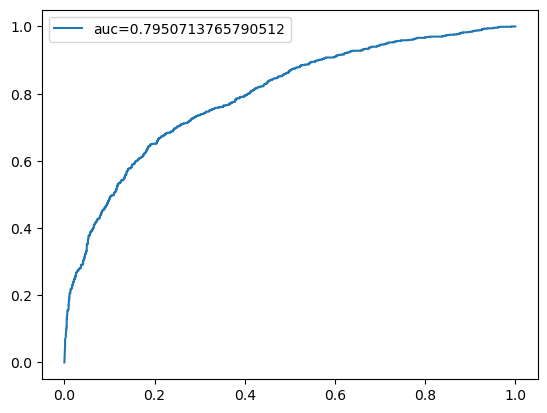

In [67]:
fpr, tpr, _ = metrics.roc_curve(yy['PET_jco'], yy['probs'])
auc = metrics.roc_auc_score(yy['PET_jco'], yy['probs'])
plt.plot(fpr, tpr, label = f'auc={str(auc)}')
plt.legend()
plt.show()

In [61]:
import shutil

In [66]:
manual_review = {
    'super_squished':['8139510_pt_0.png', '42968559_pt_0.png'],
    'obese and very low quality study':['8347044_pt_0.png', '8967176_pt_0.png'],
    'low signal': ['9416225_pt_0.png', '9785456_pt_0.png', '10024518_pt_0.png', '22994705_pt_0.png', '38325709_pt_0.png'],
    'low_penetrance': ['9502883_pt_0.png'],
    'streak line artifacts': ['9637819_pt_1.png', '9742009_pt_1.png'],
    'just weird': ['9816152_pt_0.png', '13316510_pt_0.png', '24910602_pt_0.png', '27342283_pt_0.png', '30992368_pt_3.png'],
    'head_only': ['36688967_pt_2.png'],
    'incomplete window': ['40169610_pt_2.png'	, '40243357_pt_2.png', '40254922_pt_2.png', '40271259_pt_2.png', '40352759_pt_2.png'],
    'leg_only': ['9940114_pt_0.png']
}

rt = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_thumbnails_png_curated'
savepath = '/gpfs/home/kn2347/MARS/manualreview'
for x in manual_review.keys():
    os.makedirs(os.path.join(savepath, x), exist_ok=True)
    ids = manual_review[x]
    for z in ids:
        oldpath = os.path.join(rt, z)
        newpath = os.path.join(savepath, x, z)
        shutil.copy(oldpath, newpath)


In [71]:
df

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,corrections,pixel_unit,frame_duration,tracer,tracer_injection_time,tracer_dose,tracer_halflife,image_filter,contrast_route,axial_fov
0,10002388,10002388_pt_0.h5,10002388_pt_0.pkl,10002388/10002388_pt_0.h5,081Y,M,106.594221,UNKNOWN,10002388,1.2.840.114350.2.232.2.798268.2.86568933.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,105100.0,5.953300e+08,6586.2,NaN,NaN,1860.00
1,10024518,10024518_pt_0.h5,10024518_pt_0.pkl,10024518/10024518_pt_0.h5,059Y,M,130.000000,NaN,10024518,1.2.840.113619.2.55.3.2550794926.409.143108503...,...,DECY|ATTN|SCAT|DTIM|RAN|DCAL|SLSENS|NORM,BQML,120000.0,FDG -- fluorodeoxyglucose,101100.0,4.922128e+08,6588.0,NaN,NaN,1095.45
2,10032528,10032528_pt_1.h5,10032528_pt_1.pkl,10032528/10032528_pt_1.h5,045Y,F,67.585272,NaN,10032528,1.3.12.2.1107.5.1.4.11052.30000015051113231648...,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,81600.0,5.513000e+08,6586.2,NaN,NaN,852.00
3,10050499,10050499_pt_0.h5,10050499_pt_0.pkl,10050499/10050499_pt_0.h5,065Y,M,143.788800,UNKNOWN,10050499,1.2.840.114350.2.232.2.798268.2.88694207.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,105500.0,5.871900e+08,6586.2,NaN,NaN,1983.00
4,10057383,10057383_pt_0.h5,10057383_pt_0.pkl,10057383/10057383_pt_0.h5,056Y,F,79.832267,UNKNOWN,10057383,1.2.840.114350.2.232.2.798268.2.88519269.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,85700.0,5.598100e+08,6586.2,NaN,NaN,1860.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1558,9969440,9969440_pt_0.h5,9969440_pt_0.pkl,9969440/9969440_pt_0.h5,058Y,M,64.410125,UNKNOWN,9969440,1.2.840.114350.2.232.2.798268.2.86232892.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,90800.0,5.287300e+08,6586.2,NaN,NaN,1860.00
1559,9969540,9969540_pt_0.h5,9969540_pt_0.pkl,9969540/9969540_pt_0.h5,069Y,M,77.110713,UNKNOWN,9969540,1.2.840.114350.2.232.2.798268.2.86232954.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,73600.0,5.709100e+08,6586.2,NaN,NaN,1860.00
1560,9971489,9971489_pt_0.h5,9971489_pt_0.pkl,9971489/9971489_pt_0.h5,062Y,F,60.327793,NaN,9971489,1.2.840.114350.2.232.2.798268.2.80532574.1,...,NORM|DTIM|ATTN|SCAT|RADL|DECY,BQML,120000.0,FDG,120500.0,5.772000e+08,6586.2,NaN,NaN,1675.00
1561,9988177,9988177_pt_0.h5,9988177_pt_0.pkl,9988177/9988177_pt_0.h5,072Y,F,70.370000,UNKNOWN,9988177,1.2.840.114350.2.232.2.798268.2.86811327.1,...,RAN|DTIM|NORM|ATTN|SCAT|DECY,BQML,120000.0,NaN,140000.0,5.291000e+08,6586.2,NaN,NaN,1675.00


In [73]:
df[df['filename'] == '42968559_pt_0.h5']

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,corrections,pixel_unit,frame_duration,tracer,tracer_injection_time,tracer_dose,tracer_halflife,image_filter,contrast_route,axial_fov
1244,42968559,42968559_pt_0.h5,42968559_pt_0.pkl,42968559/42968559_pt_0.h5,071Y,F,63.0,NaN,42968559,1.2.840.113619.2.55.3.2567586088.280.171518662...,...,DECY|ATTN|SCAT|DTIM|RAN|DCAL|SLSENS|NORM,BQML,150000.0,FDG -- fluorodeoxyglucose,75000.0,527512224.0,6588.0,NaN,NaN,526.47


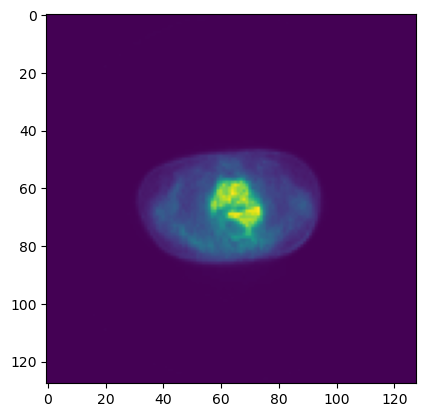

In [102]:
import h5py
f = h5py.File('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/42968559/42968559_pt_0.h5', 'r')
vv = f['image']

# convert vv from HDF5 dataset to numpy array
vv_array = np.array(vv)
plt.imshow(vv_array[:,:,100])